# Experiment 1 — Extraction quality & method comparison (RQ1, RQ2)

**Question.** Can we automatically extract the research gaps authors wrote (their *Limitations* and *Future Work*), and does the improved pipeline beat the baseline?

**Data.** Author-labelled gold sections from the unarXive open subset — a 10-paper ablation set (v1/v2a/v2b) and a 100-paper full run.

**What this notebook does.** It *loads and presents* metrics produced by the full Gap2Idea pipeline; it does **not** call any model. Two stages are reported:
- **Stage 1 (regex / PDF-layout):** how well the tool locates the gap *sections* — ROUGE vs the gold section.
- **Stage 2 (LLM):** how well the extracted gap *sentences* recover the gold (`recovery@tau`) without inventing content (`hallucination@tau`).

> Results produced by the full pipeline in the Gap2Idea repo; this notebook only reads the checked-in result files under `../../data/`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path

DATA = Path("..") / ".." / "data"
pd.options.display.float_format = lambda x: f"{x:.3f}"

def stage_means(df, stage):
    sub = df[df["stage"] == stage]
    if sub.empty:
        return pd.Series(dtype=float)
    return sub.pivot_table(index="id", columns="metric", values="value").mean()

def show_pngs(folder):
    for p in sorted(Path(folder).glob("*.png")):
        plt.figure(figsize=(7, 4)); plt.imshow(mpimg.imread(p)); plt.axis("off")
        plt.title(p.stem); plt.show()

## Part A — Pipeline ablation (v1 -> v2a -> v2b), N = 10 papers
The three variants differ only in how they *find* the gap sections: **v1** plain-text regex, **v2a** an expanded keyword vocabulary, **v2b** uses the PDF layout (headings/fonts).

In [2]:
benches = {"v1 (text+regex)": "bench", "v2a (text+vocab)": "bench_v2a", "v2b (PDF+style)": "bench_v2b"}
dfs = {name: pd.read_csv(DATA / d / "metrics.tsv", sep="\t") for name, d in benches.items()}
for name, df in dfs.items():
    print(f"{name:18s} | papers={df['id'].nunique():3d} | stages={sorted(df['stage'].unique())}")

v1 (text+regex)    | papers= 10 | stages=['llm_gap', 'regex_section']
v2a (text+vocab)   | papers= 10 | stages=['regex_section']
v2b (PDF+style)    | papers= 10 | stages=['llm_gap', 'pipeline_vs_oracle', 'regex_section']


In [3]:
rows = []
for name, df in dfs.items():
    m = stage_means(df, "regex_section")
    rows.append({"variant": name, "rouge1_f": m.get("rouge1_f"),
                 "rouge2_f": m.get("rouge2_f"), "rougeL_f": m.get("rougeL_f")})
ablation_stage1 = pd.DataFrame(rows).set_index("variant")
ablation_stage1

,rouge1_f,rouge2_f,rougeL_f
variant,,,
v1 (text+regex),0.246,0.125,0.158
v2a (text+vocab),0.246,0.125,0.158
v2b (PDF+style),0.459,0.359,0.411


**Stage 1 (section finding).** Vocabulary alone (v2a) does not improve over v1 on flat text; reading the PDF layout (v2b) is the real jump.

In [4]:
rows = []
for name, df in dfs.items():
    m = stage_means(df, "llm_gap")
    if m.empty:
        continue
    rows.append({"variant": name,
                 "recovery@0.6": m.get("recovery_at_0.6"),
                 "hallucination@0.6": m.get("hallucination_at_0.6"),
                 "mean_sim_to_gold": m.get("mean_sim_to_gold"),
                 "n_gaps": m.get("n_gaps")})
ablation_stage2 = pd.DataFrame(rows).set_index("variant")
ablation_stage2

,recovery@0.6,hallucination@0.6,mean_sim_to_gold,n_gaps
variant,,,,
v1 (text+regex),0.400,0.100,0.515,1.100
v2b (PDF+style),0.700,0.150,0.757,1.700


**Stage 2 (LLM gap sentences).** Recovery of gold gap sentences rises and hallucination falls with the PDF-aware variant. (v2a has no Stage-2 row: it was run Stage-1 only.)

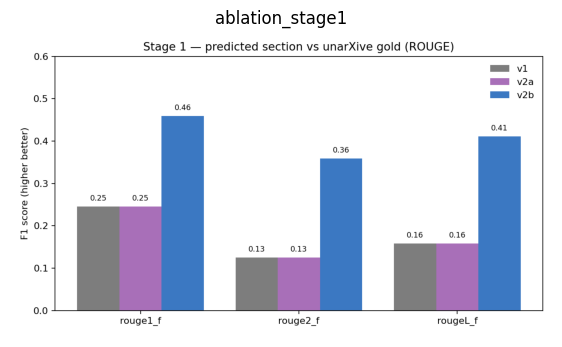

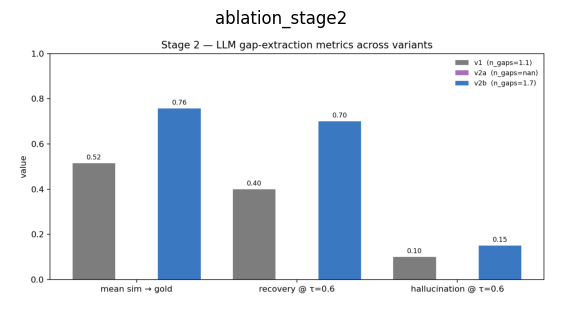

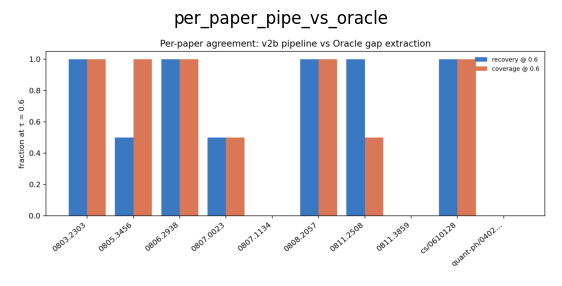

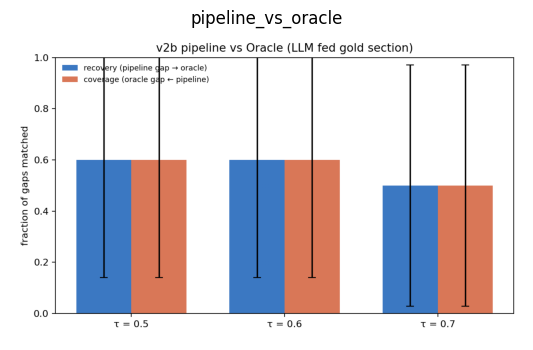

In [5]:
show_pngs(DATA / "bench_ablation_plots")

## Part B — Full-scale run, N = 100 papers
The production (v2b-style) pipeline over 100 papers.

In [6]:
n100 = pd.read_csv(DATA / "bench_n100" / "metrics.tsv", sep="\t")
s1 = stage_means(n100, "regex_section")
s2 = stage_means(n100, "llm_gap")
summary = pd.DataFrame({"value": [
    s1.get("rouge1_f"), s1.get("rougeL_f"),
    s2.get("recovery_at_0.6"), s2.get("hallucination_at_0.6"), s2.get("n_gaps"),
]}, index=["rouge1_f (stage1)", "rougeL_f (stage1)",
           "recovery@0.6 (stage2)", "hallucination@0.6 (stage2)", "avg n_gaps/paper"])
summary

,value
rouge1_f (stage1),0.506
rougeL_f (stage1),0.454
recovery@0.6 (stage2),0.630
hallucination@0.6 (stage2),0.113
avg n_gaps/paper,1.610


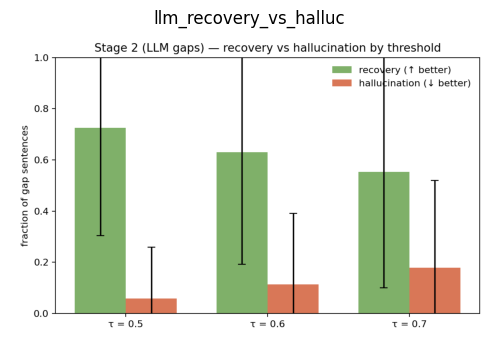

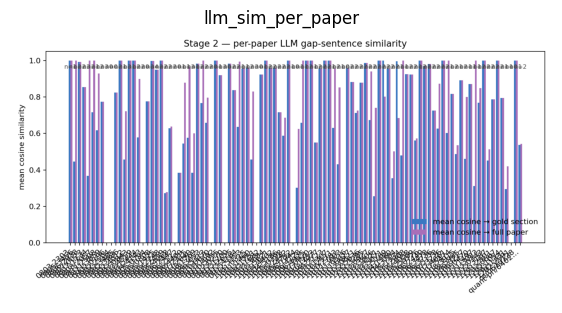

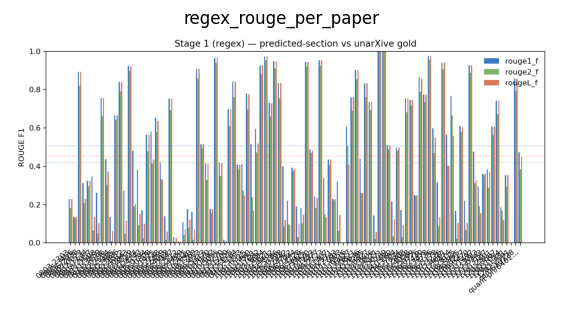

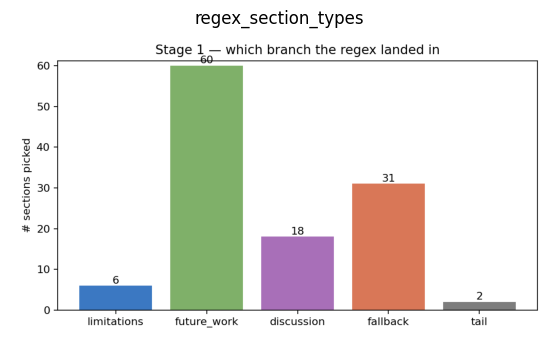

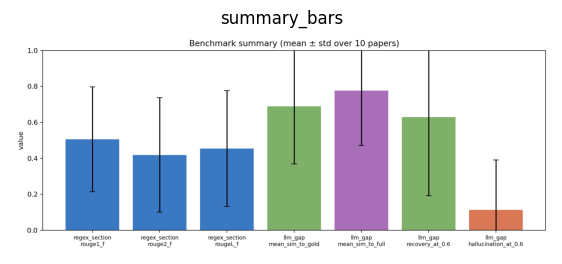

In [7]:
show_pngs(DATA / "bench_n100" / "plots")

### What the tool actually pulled out
Distribution of extracted gap types and a few verbatim examples.

In [8]:
gaps = pd.read_csv(DATA / "bench_n100" / "gaps.tsv", sep="\t")
print(f"total extracted gaps: {len(gaps)}\n")
print(gaps["gap_type"].value_counts())
print("\nexamples:")
for _, r in gaps.sample(min(4, len(gaps)), random_state=0).iterrows():
    print(f"  [{r['gap_type']}] {str(r['gap_sentence'])[:140]}")

total extracted gaps: 161

gap_type
future_work     80
open_problem    44
limitation      37
Name: count, dtype: int64

examples:
  [limitation] Another point is that the implementation don’t handle yet the case that two points have equal coordinates.
  [open_problem] The cases of related and unrelated machines have also many open problems.
  [open_problem] Quantum Nambu Dynamics of Surfaces [3, 8, 9], raises also the issue of possible exis- tence of Quantum Strange Attractors.
  [limitation] The coagulation algorithm begins to break down when (i) a few large objects contain most of mass in the grid and (ii) the gravity of these o


## Findings
- **RQ1 (method comparison).** The PDF-layout variant (v2b) roughly doubles Stage-1 ROUGE (about 0.25 -> 0.46) and lifts Stage-2 recovery@0.6 (0.40 -> 0.70) over the v1 baseline; vocabulary alone (v2a) does not help.
- **RQ2 (extraction quality).** On 100 papers the pipeline reaches rouge1_f about 0.51 (Stage 1) and recovery@0.6 about 0.63 with hallucination@0.6 about 0.11 (Stage 2) against the human gold sections.

**Next step.** Add a formal significance test (McNemar / bootstrap) on the paired per-paper scores to back the RQ1 claim statistically.